# LOLA: reconocimiento topográfico en un radio de 100 m

Modifica las coordenadas y los umbrales de la celda de configuración y ejecuta de arriba abajo.
Se busca **una superficie circular candidata dentro del entorno de 100 m**, además de resumir
la topografía del entorno completo. El tamaño de esa superficie se configura por separado.

**Sí se puede consultar LOLA sin descargar un DEM lunar completo.** Los productos polares
de NASA PGDA se distribuyen como COG: Rasterio/GDAL solicita por HTTP Range las cabeceras
y los bloques que intersectan el recorte. Se descargan bloques completos, no exclusivamente
los píxeles del círculo; el volumen depende de la compresión y del tamaño de bloque.

**Alcance:** esto es un filtro topográfico exploratorio. Una candidata no certifica un alunizaje
ni demuestra ausencia de rocas, cráteres pequeños o peligros entre muestras. Los umbrales son
ejemplos editables, no requisitos de una misión. La viabilidad de alunizaje queda NO DETERMINADA.

## Datos y cobertura

La selección automática usa COG polares: 10 m/píxel desde ±83°, 20 m desde ±80°,
30 m desde ±75° y 60 m desde ±60°. Se leen elevación (LDEM), resolución efectiva
(EFFRES), error de altura (ERR) y recuento de retornos (LDEC). La malla interpolada
no equivale a mediciones independientes en cada píxel.

Fuera de esos rangos se consulta el GeoTIFF global LOLA de USGS, de unos 118 m/píxel,
como contexto: **no tiene resolución suficiente para la búsqueda configurada**.
Ese archivo admite Range pero no es un COG. El código aplica su escala de 0.5 para obtener metros.
No se aumenta artificialmente la resolución de ningún producto.

Coordenadas: latitud planetocéntrica, norte positivo; longitud este positiva.
Los productos polares usan MOON_ME / DE421. Se deriva el CRS lunar del propio archivo;
no se emplea EPSG:4326 (Tierra). Las distancias se calculan sobre la esfera lunar de referencia.
Comprueba que las coordenadas de entrada usan el mismo marco lunar.

Fuentes:

- [NASA PGDA 90: polo sur y definición de las capas](https://pgda.gsfc.nasa.gov/products/90),
  Barker et al. (2023), [doi:10.3847/PSJ/acf3e1](https://doi.org/10.3847/PSJ/acf3e1).
- [NASA PGDA 98: polo norte](https://pgda.gsfc.nasa.gov/products/98),
  Barker et al. (2025), [doi:10.3847/PSJ/adbc9d](https://doi.org/10.3847/PSJ/adbc9d).
- [USGS: LOLA global de 118 m y escala vertical](https://astrogeology.usgs.gov/search/map/moon_lro_lola_dem_118m).
- [Rasterio: lectura por ventanas](https://rasterio.readthedocs.io/en/stable/topics/windowed-rw.html)
  y [GDAL: /vsicurl/](https://gdal.org/en/stable/user/virtual_file_systems.html#vsicurl-http-https-ftp-files-random-access).

Para profundizar: [LOLA polar de 5 m y limitaciones de interpolación](https://pgda.gsfc.nasa.gov/products/78)
y [catálogo de DTM LROC NAC](https://data.lroc.im-ldi.com/lroc/view_rdr/SHAPEFILE_NAC_DTMS).
Una malla más fina tampoco resuelve por sí sola los obstáculos de tamaño inferior al píxel.

## Entorno

Selecciona el kernel Python de `.venv`. Las dependencias están registradas en `pyproject.toml`;
desde una terminal en la raíz del repositorio puedes ejecutar `uv sync`.
Si el editor solicita instalar un kernel, ejecuta `uv pip install ipykernel`.
Si usas otro entorno, instala allí `numpy pandas matplotlib requests rasterio pyproj ipykernel`.
El análisis requiere Internet, no credenciales. No guarda ningún DEM completo en disco.

In [10]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import rasterio
from rasterio.windows import Window
from pyproj import CRS, Transformer, Geod
from IPython.display import display

# PUNTO DE ENTRADA: ejemplo ilustrativo del polo sur, no un emplazamiento validado.
LATITUD_DEG = 0.67416
LONGITUD_DEG = 23.47314    # Este positivo; acepta [-180, 360], normaliza a [-180, 180).
RADIO_ESTUDIO_M = 100.0   # Radio del entorno; diámetro = 200 m.
RADIO_SUPERFICIE_M = 20.0 # Superficie circular que buscamos: radio 20 m, diámetro 40 m.

# CRITERIOS ILUSTRATIVOS: ajústalos a los requisitos reales del vehículo.
PENDIENTE_MAX_DEG = 5.0
RUGOSIDAD_LOCAL_MAX_M = 0.5  # RMS de residuos de plano en ventanas 3x3.
RESIDUO_SUPERFICIE_MAX_M = 1.0  # Máximo |residuo| del plano de toda la superficie candidata.
ERROR_ALTURA_MAX_M = 1.0
RESOLUCION_EFECTIVA_MAX_M = 20.0
PIXEL_MAX_M = 10.1
MIN_PIXELES_DIAMETRO = 4   # Muestreo mínimo del diámetro de la superficie candidata.
COBERTURA_MIN_FRACCION = 0.95

RADIO_LUNA_M = 1_737_400.0
GEOD_LUNA = Geod(a=RADIO_LUNA_M, b=RADIO_LUNA_M)
GDAL_OPCIONES = {
    'GDAL_DISABLE_READDIR_ON_OPEN': 'EMPTY_DIR',
    'CPL_VSIL_CURL_ALLOWED_EXTENSIONS': '.tif,.TIF',
    'GDAL_HTTP_TIMEOUT': '30',
    'GDAL_HTTP_CONNECTTIMEOUT': '15',
    'GDAL_HTTP_MAX_RETRY': '3',
    'GDAL_HTTP_RETRY_DELAY': '1',
    'GDAL_HTTP_RETRY_CODES': '403,429,500,502,503,504',
    'CPL_VSIL_CURL_USE_HEAD': 'YES',
    'GDAL_HTTP_MULTIRANGE': 'SERIAL',
    'GDAL_HTTP_USERAGENT': requests.utils.default_user_agent(),
}

## Lectura remota del recorte

Antes de abrir cada archivo se comprueba una petición `Range: bytes=0-31`.
Si el servidor no devuelve `206 Partial Content`, se detiene esa lectura.
`/vsicurl/` evita el modo de descarga completa. Se añade un margen para calcular
los planos locales sin usar vecinos inexistentes en el borde de los 100 m.
Los fallos de las capas de calidad se muestran y dejan la calidad desconocida.

In [11]:
def validar_entrada(lat, lon, radio, radio_superficie):
    if not all(np.isfinite(v) for v in (lat, lon, radio, radio_superficie)):
        raise ValueError('Las coordenadas y los radios deben ser finitos.')
    if not -90 <= lat <= 90 or not -180 <= lon <= 360:
        raise ValueError('Latitud en [-90,90] y longitud este en [-180,360].')
    if not 0 < radio_superficie < radio <= 5000:
        raise ValueError('Se requiere 0 < radio_superficie < radio_estudio <= 5000 m.')
    return float(lat), float((lon + 180) % 360 - 180)


def seleccionar_fuente(lat):
    for limite, pixel in ((83, 10), (80, 20), (75, 30), (60, 60)):
        if abs(lat) >= limite:
            hemisferio = 'S' if lat < 0 else 'N'
            carpeta = 'LOLA_20mpp' if lat < 0 else 'LOLA_20mpp_NP'
            base = f'https://pgda.gsfc.nasa.gov/data/{carpeta}/'
            sufijo = f'{limite}{hemisferio}_{pixel}MPP_ADJ'
            return {
                'nombre': f'LOLA PGDA {sufijo} (COG)', 'global': False,
                'urls': {
                    'z': base + f'LDEM_{sufijo}.TIF',
                    'efectiva': base + f'LDEM_{sufijo}_EFFRES.TIF',
                    'error': base + f'LDEM_{sufijo}_ERR.TIF',
                    'cuentas': base + f'LDEC_{sufijo}.TIF',
                },
            }
    return {
        'nombre': 'LOLA global USGS 118 m (GeoTIFF con Range; solo contexto)',
        'global': True,
        'urls': {'z': 'https://planetarymaps.usgs.gov/mosaic/'
                      'Lunar_LRO_LOLA_Global_LDEM_118m_Mar2014.tif'},
    }


def comprobar_range(url):
    with requests.get(url, headers={'Range': 'bytes=0-31', 'Accept-Encoding': 'identity'},
                      stream=True, timeout=(15, 30)) as resp:
        rango = resp.headers.get('Content-Range', '')
        if resp.status_code != 206 or not rango.startswith('bytes 0-31/'):
            raise RuntimeError(f'Sin HTTP Range válido ({resp.status_code}): {url}')
        cabecera = resp.raw.read(32)
        if cabecera[:4] not in (b'II*\x00', b'MM\x00*', b'II+\x00', b'MM\x00+'):
            raise RuntimeError(f'La respuesta no es TIFF/BigTIFF: {url}')
        return int(rango.rsplit('/', 1)[1])


def leer_ventana(src, ventana, envolver=False):
    # Rellena fuera de cobertura con NaN. En el DEM global une ambos lados de ±180°.
    c0, r0, ancho, alto = map(int, ventana.flatten())
    salida = np.full((alto, ancho), np.nan)
    ra, rb = max(0, r0), min(src.height, r0 + alto)
    if rb <= ra:
        return salida
    for inicio in range(0, ancho, src.width) if envolver else (0,):
        # El bucle interior divide también una ventana que cruza la costura del mapa.
        pos = inicio
        fin = min(ancho, inicio + src.width) if envolver else ancho
        while pos < fin:
            col = (c0 + pos) % src.width if envolver else max(0, c0 + pos)
            if not envolver and c0 + pos < 0:
                pos = min(fin, -c0)
                continue
            largo = min(fin - pos, src.width - col)
            if largo <= 0:
                break
            datos = src.read(1, window=Window(col, ra, largo, rb - ra), masked=True)
            datos = datos.astype('float64').filled(np.nan)
            salida[ra-r0:rb-r0, pos:pos+largo] = datos * src.scales[0] + src.offsets[0]
            pos += largo
    return salida


def cargar_recorte(lat, lon, radio):
    fuente = seleccionar_fuente(lat)
    capas, avisos, auditoria = {}, [], []
    with rasterio.Env(**GDAL_OPCIONES):
        for nombre, url in fuente['urls'].items():
            try:
                tamano = comprobar_range(url)
                with rasterio.open('/vsicurl/' + url) as src:
                    if nombre == 'z':
                        crs = CRS.from_wkt(src.crs.to_wkt())
                        if not math.isclose(crs.ellipsoid.semi_major_metre, RADIO_LUNA_M, abs_tol=1):
                            raise ValueError('Radio del CRS incompatible con la referencia lunar.')
                        a_fuente = Transformer.from_crs(crs.geodetic_crs, crs, always_xy=True)
                        x0, y0 = a_fuente.transform(lon, lat)
                        margen = 4 * max(src.res)
                        az = np.linspace(0, 360, 361)
                        lons, lats, _ = GEOD_LUNA.fwd(np.full(az.shape, lon), np.full(az.shape, lat),
                                                    az, np.full(az.shape, radio + margen))
                        xs, ys = map(np.asarray, a_fuente.transform(lons, lats))
                        if fuente['global']:
                            periodo = src.width * src.res[0]
                            xs = x0 + (xs - x0 + periodo/2) % periodo - periodo/2
                        cols, filas = (~src.transform) * (xs, ys)
                        c0, r0 = int(np.floor(cols.min())), int(np.floor(filas.min()))
                        c1, r1 = int(np.ceil(cols.max())), int(np.ceil(filas.max()))
                        ventana = Window(c0, r0, c1-c0, r1-r0)
                        if ventana.width * ventana.height > 1_000_000:
                            raise ValueError('Recorte demasiado grande: reduce el radio.')
                        original = (src.crs, src.transform, src.shape)
                        transform = src.window_transform(ventana)
                    elif (src.crs, src.transform, src.shape) != original:
                        raise ValueError(f'La capa {nombre} no coincide con la malla del DEM.')
                    capas[nombre] = leer_ventana(src, ventana, fuente['global'])
                    auditoria.append({'capa': nombre, 'HTTP': 206, 'archivo_GB': tamano/1e9,
                                      'layout': src.tags(ns='IMAGE_STRUCTURE').get('LAYOUT', 'no COG'),
                                      'bloque_px': str(src.block_shapes[0]),
                                      'escala': src.scales[0], 'offset': src.offsets[0], 'url': url})
            except (requests.RequestException, rasterio.errors.RasterioError, ValueError, RuntimeError) as exc:
                if nombre == 'z':
                    raise RuntimeError('No se pudo leer el DEM remoto. Revisa conexión y URL. ' + str(exc)) from exc
                avisos.append(f'Capa {nombre} no disponible: {exc}')
    forma = capas['z'].shape
    for nombre in ('efectiva', 'error', 'cuentas'):
        capas.setdefault(nombre, np.full(forma, np.nan))
    filas, cols = np.indices(forma)
    xs, ys = transform * (cols + 0.5, filas + 0.5)
    al_geo = Transformer.from_crs(crs, crs.geodetic_crs, always_xy=True)
    lons, lats = al_geo.transform(xs, ys)
    local = CRS.from_proj4(f'+proj=aeqd +lat_0={lat} +lon_0={lon} '
                          f'+a={RADIO_LUNA_M} +b={RADIO_LUNA_M} +units=m +no_defs')
    al_local = Transformer.from_crs(crs.geodetic_crs, local, always_xy=True)
    este, norte = map(np.asarray, al_local.transform(lons, lats))
    # AEQD conserva la distancia desde el punto central. No se remuestrea la elevación.
    dx = np.median(np.hypot(np.diff(este, axis=1), np.diff(norte, axis=1)))
    dy = np.median(np.hypot(np.diff(este, axis=0), np.diff(norte, axis=0)))
    return dict(capas=capas, este=este, norte=norte, lons=np.asarray(lons), lats=np.asarray(lats),
                dx=float(dx), dy=float(dy), fuente=fuente, avisos=avisos,
                auditoria=pd.DataFrame(auditoria), crs=crs, transform=transform)

## Criterios topográficos

Para cada píxel se ajusta un plano `z = a·este + b·norte + c` a sus vecinos 3×3.
La pendiente es `atan(sqrt(a²+b²))`; la rugosidad local es el RMS de los residuos.
Un plano inclinado tiene rugosidad cero, pero conserva su pendiente.
Esta rugosidad calculada sobre el DEM **no es** el producto oficial LDRM ni detecta rocas.

Se ajusta también un plano al círculo completo de 100 m para resumir su relieve.
Después se buscan discos del radio indicado, completamente contenidos en los 100 m:
todos sus píxeles deben pasar pendiente, rugosidad, error y resolución efectiva.
Además se comprueba la pendiente y el máximo residuo del plano de cada disco.
Se añade media diagonal de píxel al disco al verificar sus vecinos, como margen conservador.
No se aceptan NaN ni vecinos incompletos. Los recuentos LDEC se resumen como soporte observado,
sin exigir un retorno en cada píxel ni tratar la interpolación como medición directa.

In [12]:
def ajustar_plano(x, y, z):
    if len(z) < 6 or not np.isfinite(z).all():
        return np.nan, np.nan, np.nan
    matriz = np.column_stack((x-x.mean(), y-y.mean(), np.ones(len(z))))
    coef, _, rango, _ = np.linalg.lstsq(matriz, z, rcond=None)
    if rango < 3:
        return np.nan, np.nan, np.nan
    residuos = z - matriz @ coef
    pendiente = np.degrees(np.arctan(np.hypot(coef[0], coef[1])))
    return float(pendiente), float(np.sqrt(np.mean(residuos**2))), float(np.max(np.abs(residuos)))


def mapas_locales(z, este, norte):
    pendiente = np.full(z.shape, np.nan)
    rugosidad = np.full(z.shape, np.nan)
    for i in range(1, z.shape[0]-1):
        for j in range(1, z.shape[1]-1):
            trozo = np.s_[i-1:i+2, j-1:j+2]
            pendiente[i,j], rugosidad[i,j], _ = ajustar_plano(
                este[trozo].ravel(), norte[trozo].ravel(), z[trozo].ravel())
    return pendiente, rugosidad


def analizar_recorte(datos, radio, radio_superficie):
    capas, este, norte = datos['capas'], datos['este'], datos['norte']
    z = capas['z']
    distancia = np.hypot(este, norte)
    dentro = distancia <= radio
    total = int(dentro.sum())
    if total == 0:
        raise ValueError('Ningún centro de píxel cae en el círculo; se necesitan datos más finos.')
    valido = dentro & np.isfinite(z)
    pendiente, rugosidad = mapas_locales(z, este, norte)
    evaluable = valido & np.isfinite(pendiente) & np.isfinite(rugosidad)
    calidad = (evaluable & np.isfinite(capas['efectiva']) & np.isfinite(capas['error'])
               & (capas['efectiva'] >= 0) & (capas['efectiva'] <= RESOLUCION_EFECTIVA_MAX_M)
               & (capas['error'] >= 0) & (capas['error'] <= ERROR_ALTURA_MAX_M))
    suave = evaluable & (pendiente <= PENDIENTE_MAX_DEG) & (rugosidad <= RUGOSIDAD_LOCAL_MAX_M)
    apto = suave & calidad
    pixel = max(datos['dx'], datos['dy'])
    resolucion_suficiente = (pixel <= PIXEL_MAX_M
                            and 2*radio_superficie/pixel >= MIN_PIXELES_DIAMETRO)
    candidatas = []
    if resolucion_suficiente:
        margen_pixel = np.hypot(datos['dx'], datos['dy'])/2
        for i, j in np.argwhere(apto & (distancia + radio_superficie + margen_pixel <= radio)):
            disco = np.hypot(este-este[i,j], norte-norte[i,j]) <= radio_superficie + margen_pixel
            if not apto[disco].all():
                continue
            p, rms, max_res = ajustar_plano(este[disco], norte[disco], z[disco])
            if p <= PENDIENTE_MAX_DEG and max_res <= RESIDUO_SUPERFICIE_MAX_M:
                candidatas.append({'latitud_deg': datos['lats'][i,j],
                                   'longitud_deg': (datos['lons'][i,j]+180)%360-180,
                                   'este_m': este[i,j], 'norte_m': norte[i,j],
                                   'distancia_al_punto_m': distancia[i,j], 'pendiente_plano_deg': p,
                                   'rms_plano_m': rms, 'max_residuo_m': max_res,
                                   'fila': int(i), 'columna': int(j)})
    columnas = ['latitud_deg', 'longitud_deg', 'este_m', 'norte_m', 'distancia_al_punto_m',
                'pendiente_plano_deg', 'rms_plano_m', 'max_residuo_m', 'fila', 'columna']
    candidatas = pd.DataFrame(candidatas, columns=columnas).sort_values(
        ['rms_plano_m', 'distancia_al_punto_m'], ignore_index=True)
    cobertura = float(calidad.sum()/total)
    if len(candidatas):
        estado = 'HAY CANDIDATAS TOPOGRÁFICAS: requieren comprobación con datos más finos'
    elif not resolucion_suficiente or cobertura < COBERTURA_MIN_FRACCION:
        estado = 'DATOS INSUFICIENTES para descartar o proponer una superficie'
    else:
        estado = 'SIN CANDIDATAS con estos umbrales a la escala del DEM'

    def percentil(array, mascara, q):
        valores = array[mascara & np.isfinite(array)]
        return float(np.percentile(valores, q)) if valores.size else np.nan

    p_global, rms_global, max_global = ajustar_plano(este[valido], norte[valido], z[valido])
    resumen = {
        'estado_topografico': estado, 'viabilidad_alunizaje': 'NO DETERMINADA',
        'radio_estudio_m': radio, 'radio_superficie_buscada_m': radio_superficie,
        'pixel_local_max_m': pixel, 'resolucion_suficiente': bool(resolucion_suficiente),
        'pixeles_en_circulo': total, 'elevacion_valida_pct': 100*valido.sum()/total,
        'calidad_suficiente_pct': 100*cobertura,
        'pixeles_suaves_pct_del_total': 100*suave.sum()/total,
        'pixeles_suaves_y_calidad_pct_del_total': 100*apto.sum()/total,
        'pixeles_con_retornos_pct_del_total': 100*np.count_nonzero(valido & (capas['cuentas']>0))/total
            if np.isfinite(capas['cuentas'][dentro]).any() else np.nan,
        'pendiente_local_p95_deg': percentil(pendiente, evaluable, 95),
        'rugosidad_local_p95_m': percentil(rugosidad, evaluable, 95),
        'resolucion_efectiva_p95_m': percentil(capas['efectiva'], valido, 95),
        'error_altura_p95_m': percentil(capas['error'], valido, 95),
        'pendiente_plano_entorno_deg': p_global, 'rms_plano_entorno_m': rms_global,
        'max_residuo_plano_entorno_m': max_global, 'numero_centros_candidatos': len(candidatas),
    }
    return dict(resumen=resumen, candidatas=candidatas, dentro=dentro,
                pendiente=pendiente, rugosidad=rugosidad, calidad=calidad, apto=apto)

## Ejecutar la consulta y ver resultados

`datos` conserva los arrays del recorte y la auditoría de las URLs.
`resultado['resumen']` distingue los dos radios, cobertura y estado.
`resultado['candidatas']` contiene centros de discos que pasan el filtro; los discos pueden
solaparse y **no representan lugares independientes**. Una tabla vacía no demuestra que
el punto sea peligroso: revisa primero resolución y calidad. Los porcentajes usan como
denominador todos los centros de píxel del círculo, incluidos los datos desconocidos.

In [13]:
latitud, longitud = validar_entrada(LATITUD_DEG, LONGITUD_DEG, RADIO_ESTUDIO_M, RADIO_SUPERFICIE_M)
datos = cargar_recorte(latitud, longitud, RADIO_ESTUDIO_M)
resultado = analizar_recorte(datos, RADIO_ESTUDIO_M, RADIO_SUPERFICIE_M)

print(f'Punto: lat={latitud:.6f}°, lon este={longitud:.6f}°')
print('Fuente:', datos['fuente']['nombre'])
print(f'Recorte: {datos["capas"]["z"].shape}; paso local ≈ {datos["dx"]:.2f} × {datos["dy"]:.2f} m')
print(resultado['resumen']['estado_topografico'])
for aviso in datos['avisos']:
    print('AVISO:', aviso)
display(pd.Series(resultado['resumen'], name='valor').to_frame())
display(datos['auditoria'])
display(resultado['candidatas'].drop(columns=['fila', 'columna']).head(10))

Punto: lat=0.674160°, lon este=23.473140°
Fuente: LOLA global USGS 118 m (GeoTIFF con Range; solo contexto)
Recorte: (11, 10); paso local ≈ 118.44 × 118.45 m
DATOS INSUFICIENTES para descartar o proponer una superficie


,valor
estado_topografico,DATOS INSUFICIENTES para descartar o proponer ...
viabilidad_alunizaje,NO DETERMINADA
radio_estudio_m,100.0
radio_superficie_buscada_m,20.0
pixel_local_max_m,118.450588
resolucion_suficiente,False
pixeles_en_circulo,2
elevacion_valida_pct,100.0
calidad_suficiente_pct,0.0
pixeles_suaves_pct_del_total,100.0


,capa,HTTP,archivo_GB,layout,bloque_px,escala,offset,url
0,z,206,8.494204,no COG,"(1, 92160)",0.5,0.0,https://planetarymaps.usgs.gov/mosaic/Lunar_LR...


,latitud_deg,longitud_deg,este_m,norte_m,distancia_al_punto_m,pendiente_plano_deg,rms_plano_m,max_residuo_m


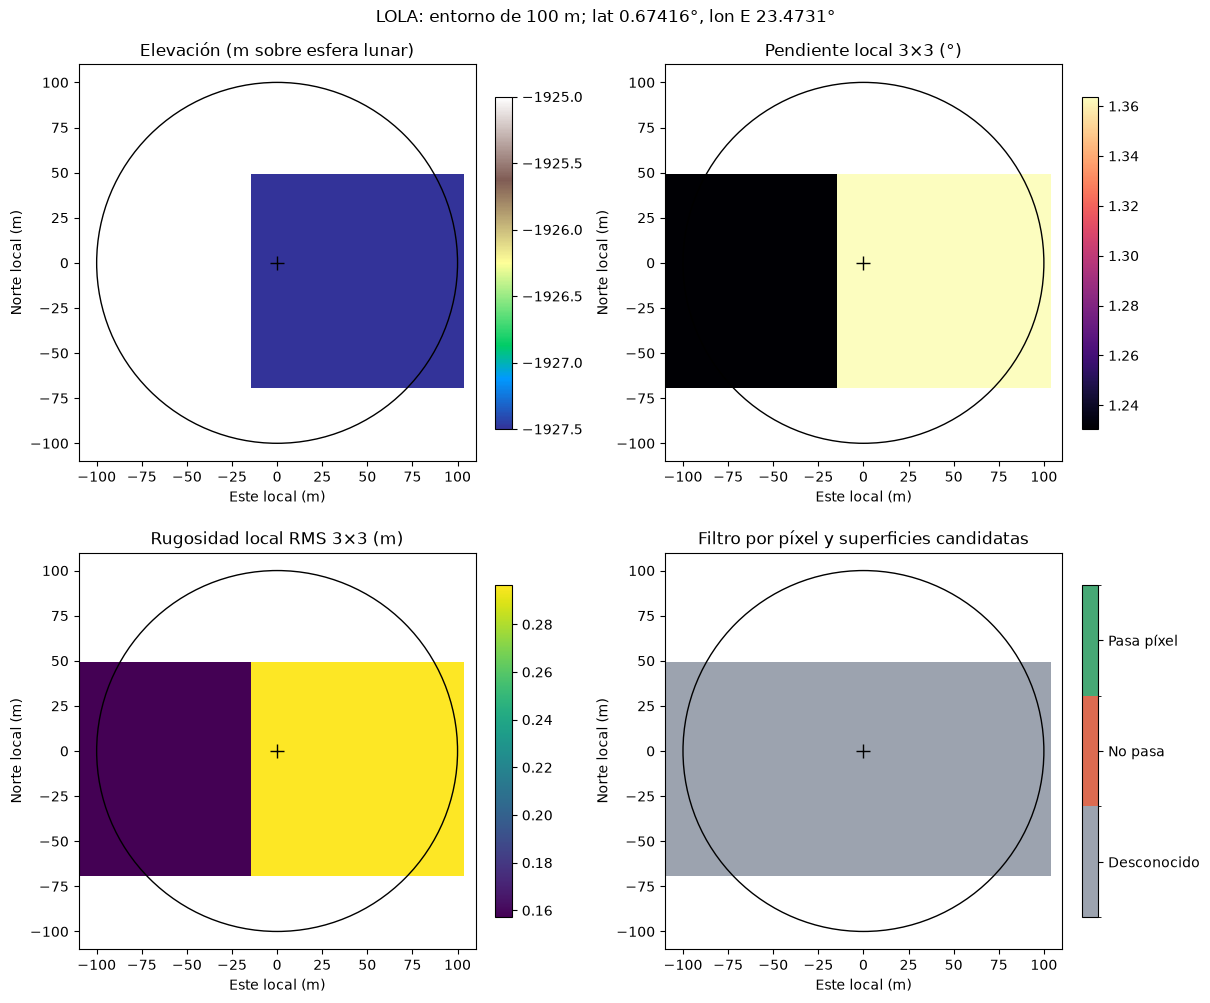

In [14]:
# Sin suavizado visual: cada celda representa una muestra del DEM.
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Circle

dentro = resultado['dentro']
estado_mapa = np.full(dentro.shape, np.nan)
estado_mapa[dentro] = 0  # Datos/calidad insuficientes.
estado_mapa[resultado['calidad']] = 1  # Calidad conocida, no pasa topografía.
estado_mapa[resultado['apto']] = 2     # Pasa el filtro por píxel; no certifica una superficie.
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
mapas = [
    (datos['capas']['z'], 'Elevación (m sobre esfera lunar)', 'terrain', None),
    (resultado['pendiente'], 'Pendiente local 3×3 (°)', 'magma', None),
    (resultado['rugosidad'], 'Rugosidad local RMS 3×3 (m)', 'viridis', None),
    (estado_mapa, 'Filtro por píxel y superficies candidatas',
     ListedColormap(['#9ca3af', '#dc6b51', '#46a875']), BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3)),
]
for ax, (array, titulo, cmap, norm) in zip(axes.flat, mapas):
    valores = np.where(dentro, array, np.nan)
    imagen = ax.pcolormesh(datos['este'], datos['norte'], np.ma.masked_invalid(valores),
                           shading='nearest', cmap=cmap, norm=norm, rasterized=True)
    barra = fig.colorbar(imagen, ax=ax, shrink=0.8)
    if norm is not None:
        barra.set_ticks([0, 1, 2], labels=['Desconocido', 'No pasa', 'Pasa píxel'])
    ax.add_patch(Circle((0, 0), RADIO_ESTUDIO_M, fill=False, color='black', linewidth=1))
    ax.plot(0, 0, '+', color='black', markersize=10)
    ax.set(title=titulo, xlabel='Este local (m)', ylabel='Norte local (m)',
           xlim=(-RADIO_ESTUDIO_M*1.1, RADIO_ESTUDIO_M*1.1),
           ylim=(-RADIO_ESTUDIO_M*1.1, RADIO_ESTUDIO_M*1.1), aspect='equal')
if not resultado['candidatas'].empty:
    mejor = resultado['candidatas'].iloc[0]
    axes[1,1].add_patch(Circle((mejor.este_m, mejor.norte_m), RADIO_SUPERFICIE_M,
                              fill=False, color='#1747df', linewidth=2, label='Primera candidata'))
    axes[1,1].legend(loc='upper right')
fig.suptitle(f'LOLA: entorno de {RADIO_ESTUDIO_M:g} m; lat {latitud:g}°, lon E {longitud:g}°')
plt.show()

## Cómo interpretar el resultado

- **HAY CANDIDATAS TOPOGRÁFICAS:** al menos un disco cumple los filtros en esta malla.
  Revisa sus coordenadas con imágenes y DTM de mayor resolución; no significa «zona limpia».
- **SIN CANDIDATAS:** el filtro no encuentra un disco con los criterios indicados y existe
  cobertura suficiente según el umbral configurado. No se demuestra imposibilidad física.
- **DATOS INSUFICIENTES:** faltan muestras/calidad o el paso espacial es demasiado grande.
  No interpretes una superficie interpolada y lisa como ausencia de obstáculos.

Para estudiar piedras y pequeños cráteres hacen falta imágenes LROC NAC y, donde existan,
DTM de mayor resolución, junto con una evaluación de incertidumbre. También quedan fuera
la capacidad portante del suelo, iluminación, comunicaciones, navegación y requisitos del vehículo.
Las distancias son sobre la esfera de referencia; no incluyen altura ni distancia sobre el relieve.